# EDA · Value Finders (Credicorp Capital)

Análisis exploratorio en dos partes:

- **Parte A · Calidad (Find the truth).** Nulos, registros y duplicados por ID, alias, fechas, valores inválidos y **cuánta data se puede salvar**. Cada conteo va con su total y su porcentaje.
- **Parte B · Exploración en soles (PEN).** Tipo de cambio, retorno y riesgo por activo, distribución, correlaciones, regímenes, eventos, fundamentales y lectura por cliente.

**Fuentes.** Los 7 CSV de `DATA_DIR` (por defecto `data/`; en Databricks, `/Volumes/credicorp_dq/bronze/landing`).
Las reglas de limpieza son las del pipeline `databricks/02_silver.py` (rama `dev_databricks`), para que el EDA y la capa silver cuenten lo mismo.

**Moneda: soles.** Credicorp usa el sol como moneda funcional desde 2014 y convierte con el **tipo de cambio de cierre publicado por la SBS**
(saldos al cierre del periodo, flujos al cierre del mes). En el dataset, `usd_pen` de `02_macro_raw.csv` hace de ese TC:
precios × `usd_pen` del mismo día; fundamentales × `usd_pen` del cierre de trimestre (solo hay TC desde 2025-08-01).

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
DATA_DIR = Path(os.environ.get("DATA_DIR", ROOT / "data"))
pd.set_option("display.max_columns", 30, "display.width", 180)
ANN = np.sqrt(252)

FILES = {
    "precios_diario": "01_market_prices_raw.csv",
    "precios_intradia": "01_market_prices_raw_expanded.csv",
    "macro": "02_macro_raw.csv",
    "fundamentales": "03_fundamentals_raw.csv",
    "referencia": "04_asset_reference.csv",
    "clientes": "05_client_profiles.csv",
    "eventos": "06_events.csv",
}
# Todo como texto y sin convertir nada a NaN: así se ve cada valor tal como viene.
raw = {k: pd.read_csv(DATA_DIR / f, encoding="utf-8-sig", dtype=str, keep_default_na=False) for k, f in FILES.items()}
N = {k: len(d) for k, d in raw.items()}  # total de registros por archivo
TOKENS_NULOS = ["N/A", "NA", "NaN", "null", "None", "-"]
NUMERICAS = {
    "precios_diario": ["open", "high", "low", "close", "volume"],
    "precios_intradia": ["open", "high", "low", "close", "volume"],
    "macro": ["us_10y_yield", "us_inflation_yoy", "usd_cop", "usd_pen", "usd_mxn", "usd_clp", "market_factor"],
    "fundamentales": ["revenue_usd_m", "ebitda_usd_m", "net_income_usd_m", "debt_usd_m", "cash_usd_m"],
}


def pct(n, total):
    return round(n / total * 100, 3) if total else np.nan


def norm_asset(s):
    # 'VF-A1' / 'VFA03' / 'VF_A6' -> 'VF_A01' (misma regex que 02_silver.py)
    n = s.str.extract(r"^VF[-_]?A?0*(\d+)$", expand=False)
    return ("VF_A" + n.str.zfill(2)).where(n.notna(), s)


def norm_issuer(s):
    n = s.str.extract(r"^ISS_?0*(\d+)$", expand=False)
    return ("ISS_" + n.str.zfill(2)).where(n.notna(), s)


def to_num(s):
    # quita separador de miles y expande sufijos K/M/B ('3635.6K' -> 3635600)
    s = s.str.strip().str.replace(",", "", regex=False)
    mult = s.str[-1].str.upper().map({"K": 1e3, "M": 1e6, "B": 1e9})
    base = pd.to_numeric(s.where(mult.isna(), s.str[:-1]), errors="coerce")
    return base * mult.fillna(1)


def to_ts(s):
    out = pd.Series(pd.NaT, index=s.index)
    for fmt in ["%Y-%m-%d %H:%M:%S", "%m/%d/%Y %H:%M:%S", "%Y-%m-%d", "%m/%d/%Y"]:
        out = out.fillna(pd.to_datetime(s, format=fmt, errors="coerce"))
    return out

# Parte A · Calidad de datos

## A1. Inventario

`% del total` es la participación de cada archivo en los registros de todo el dataset.

In [2]:
total_registros = sum(N.values())
inv = pd.DataFrame({
    "archivo": FILES.values(),
    "registros": N.values(),
    "% del total": [pct(n, total_registros) for n in N.values()],
    "columnas": [d.shape[1] for d in raw.values()],
    "celdas": [d.size for d in raw.values()],
}, index=FILES.keys())
inv.loc["TOTAL"] = ["7 archivos", total_registros, 100.0, inv.columnas.sum(), inv.celdas.sum()]
inv

,archivo,registros,% del total,columnas,celdas
precios_diario,01_market_prices_raw.csv,2175,0.402,9,19575
precios_intradia,01_market_prices_raw_expanded.csv,538836,99.533,9,4849524
macro,02_macro_raw.csv,271,0.050,9,2439
fundamentales,03_fundamentals_raw.csv,65,0.012,7,455
referencia,04_asset_reference.csv,8,0.001,7,56
clientes,05_client_profiles.csv,3,0.001,9,27
eventos,06_events.csv,5,0.001,5,25
TOTAL,7 archivos,541363,100.000,55,4872101


## A2. Cómo vienen los nulos y los números

Antes de contar nulos hay que ver **cómo** vienen. Hay celdas vacías, texto que significa "sin dato" (`N/A`) y números escritos como texto
(`3635.6K`, `1,845.7`). Spark y SQL no tratan `N/A` como nulo ni `K` como miles: si no se declara en la ingesta, el dato se pierde o se lee mal.

In [4]:
filas = []
for k, d in raw.items():
    for c in d.columns:
        v = d[c]
        es_num = c in NUMERICAS.get(k, [])
        filas.append({
            "dataset": k, "columna": c, "total": len(v),
            "vacías": int((v == "").sum()),
            "texto 'N/A'": int(v.isin(TOKENS_NULOS).sum()),
            "sufijo K/M/B": int(v.str.fullmatch(r"[0-9.,]+[KMBkmb]").sum()) if es_num else 0,
            "coma de miles": int(v.str.fullmatch(r"\d{1,3}(,\d{3})+(\.\d+)?").sum()) if es_num else 0,
        })
formatos = pd.DataFrame(filas)
formatos["con problema"] = formatos[["vacías", "texto 'N/A'", "sufijo K/M/B", "coma de miles"]].sum(axis=1)
formatos["% con problema"] = [pct(n, t) for n, t in zip(formatos["con problema"], formatos.total)]
formatos[formatos["con problema"] > 0].set_index(["dataset", "columna"])

total  vacías  texto 'N/A'  sufijo K/M/B  coma de miles  con problema  % con problema
dataset          columna                                                                                                 
precios_diario   currency            2175       4            0             0              0             4           0.184
                 volume              2175       0            3             3              0             6           0.276
precios_intradia currency          538836      35            0             0              0            35           0.006
                 close             538836      24            0             0              0            24           0.004
                 volume            538836       0           30            45              0            75           0.014
macro            us_inflation_yoy     271     258            0             0              0           258          95.203
fundamentales    revenue_usd_m         65       0            0             0              1             1           1.538
                 cash_usd_m            65       1            0             0              0             1           1.538

In [4]:
# Desde aquí: vacíos y texto tipo nulo pasan a NaN
raw = {k: d.replace([""] + TOKENS_NULOS, np.nan) for k, d in raw.items()}

## A3. Nulos por columna

In [5]:
nulos = pd.concat({k: pd.DataFrame({"nulos": d.isna().sum(), "total": len(d), "%": (d.isna().mean() * 100).round(3)})
                   for k, d in raw.items()}, names=["dataset", "columna"])
nulos_tabla = nulos[nulos.nulos > 0]
resumen_nulos = pd.DataFrame({
    "celdas nulas": [int(d.isna().sum().sum()) for d in raw.values()],
    "% de celdas": [pct(d.isna().sum().sum(), d.size) for d in raw.values()],
    "filas con algún nulo": [int(d.isna().any(axis=1).sum()) for d in raw.values()],
    "% de filas": [pct(d.isna().any(axis=1).sum(), len(d)) for d in raw.values()],
}, index=FILES.keys())
display(nulos_tabla)
resumen_nulos

nulos   total       %
dataset          columna                                
precios_diario   currency              4    2175   0.184
                 volume                3    2175   0.138
precios_intradia currency             35  538836   0.006
                 close                24  538836   0.004
                 volume               30  538836   0.006
macro            us_inflation_yoy    258     271  95.203
fundamentales    cash_usd_m            1      65   1.538

,celdas nulas,% de celdas,filas con algún nulo,% de filas
precios_diario,7,0.036,7,0.322
precios_intradia,89,0.002,89,0.017
macro,258,10.578,258,95.203
fundamentales,1,0.220,1,1.538
referencia,0,0.000,0,0.000
clientes,0,0.000,0,0.000
eventos,0,0.000,0,0.000


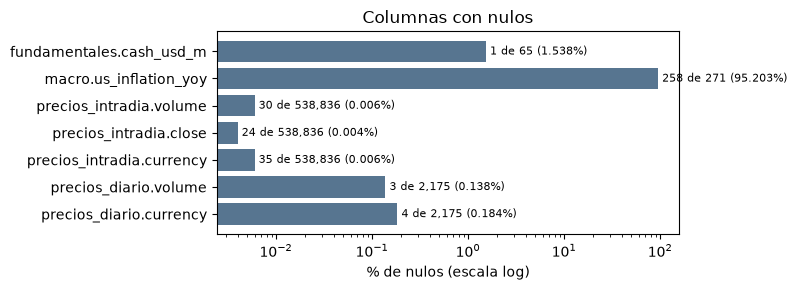

In [6]:
fig, ax = plt.subplots(figsize=(8, 3))
lbl = [f"{a}.{b}" for a, b in nulos_tabla.index]
ax.barh(lbl, nulos_tabla["%"], color="#577590")
ax.set_xscale("log"); ax.set_xlabel("% de nulos (escala log)"); ax.set_title("Columnas con nulos")
for i, (n, t, p) in enumerate(zip(nulos_tabla.nulos, nulos_tabla.total, nulos_tabla["%"])):
    ax.text(p, i, f" {n:,} de {t:,} ({p}%)", va="center", fontsize=8)
plt.tight_layout(); plt.show()

`us_inflation_yoy` es un dato **mensual** cargado en una tabla diaria: sus nulos son estructurales y se rellenan con el último valor publicado.
`currency` nula se completa desde el maestro (todo cotiza en USD). `volume` nulo no afecta, porque los retornos usan `close`.
El único nulo que obliga a descartar filas es `close` (24 barras intradía).

## A4. Registros por ID

Cuántos registros tiene cada activo o emisor, qué parte del archivo representa y qué tan completo está respecto de lo esperado:
- diario: 1 fila por día del calendario macro;
- intradía: 39 barras de 10 minutos por día de sesión;
- fundamentales: 8 trimestres por emisor.

In [7]:
def registros_por_id(d, col, canon, esperado_por_id, extra=None):
    ids = canon(d[col])
    t = pd.DataFrame({
        "registros": ids.value_counts(),
        "con alias": ids[d[col] != ids].value_counts(),
    }).fillna(0).astype(int).sort_index()
    t["% del archivo"] = (t.registros / len(d) * 100).round(3)
    t["esperados"] = esperado_por_id
    t["% completitud"] = (t.registros / t.esperados * 100).round(2)
    if extra is not None:
        t = t.join(extra)
    t.loc["TOTAL"] = [t.registros.sum(), t["con alias"].sum(), 100.0, t.esperados.sum(),
                      round(t.registros.sum() / t.esperados.sum() * 100, 2)] + ([] if extra is None else list(t[extra.columns].sum()))
    return t

ts_dia = to_ts(raw["precios_diario"].date)
ts_int = to_ts(raw["precios_intradia"].date)
dias_macro = raw["macro"].date.nunique()
dias_int = ts_int.dt.normalize().nunique()

def dups_por_id(d, ts, canon_ids):
    k = pd.DataFrame({"id": canon_ids, "ts": ts})
    return k[k.duplicated()].id.value_counts().rename("duplicados")

por_id_dia = registros_por_id(raw["precios_diario"], "asset_id", norm_asset, dias_macro,
                              dups_por_id(raw["precios_diario"], ts_dia, norm_asset(raw["precios_diario"].asset_id)).to_frame())
por_id_int = registros_por_id(raw["precios_intradia"], "asset_id", norm_asset, dias_int * 39,
                              dups_por_id(raw["precios_intradia"], ts_int, norm_asset(raw["precios_intradia"].asset_id)).to_frame())
for t in (por_id_dia, por_id_int):
    t["duplicados"] = t["duplicados"].fillna(0).astype(int)
    t["% duplicados"] = (t.duplicados / t.registros * 100).round(3)
    t["únicos"] = t.registros - t.duplicados
    t["% completitud únicos"] = (t["únicos"] / t.esperados * 100).round(2)
print(f"Precios diario · esperados por activo = {dias_macro} días del calendario macro")
display(por_id_dia)
print(f"Precios intradía · esperados por activo = {dias_int:,} días × 39 barras")
display(por_id_int)

Precios diario · esperados por activo = 271 días del calendario macro


,registros,con alias,% del archivo,esperados,% completitud,duplicados,% duplicados,únicos,% completitud únicos
asset_id,,,,,,,,,
VF_A01,273,1,12.552,271,100.74,2,0.733,271,100.0
VF_A02,272,0,12.506,271,100.37,1,0.368,271,100.0
VF_A03,272,1,12.506,271,100.37,1,0.368,271,100.0
VF_A04,271,0,12.460,271,100.00,0,0.000,271,100.0
VF_A05,272,0,12.506,271,100.37,1,0.368,271,100.0
VF_A06,272,1,12.506,271,100.37,1,0.368,271,100.0
VF_A07,271,0,12.460,271,100.00,0,0.000,271,100.0
VF_A08,272,0,12.506,271,100.37,1,0.368,271,100.0
TOTAL,2175,3,100.000,2168,100.32,7,0.322,2168,100.0


Precios intradía · esperados por activo = 1,727 días × 39 barras


,registros,con alias,% del archivo,esperados,% completitud,duplicados,% duplicados,únicos,% completitud únicos
asset_id,,,,,,,,,
VF_A01,67353,2,12.5,67353,100.00,0,0.000,67353,100.0
VF_A02,67354,0,12.5,67353,100.00,1,0.001,67353,100.0
VF_A03,67353,0,12.5,67353,100.00,0,0.000,67353,100.0
VF_A04,67357,3,12.5,67353,100.01,4,0.006,67353,100.0
VF_A05,67353,0,12.5,67353,100.00,0,0.000,67353,100.0
VF_A06,67357,11,12.5,67353,100.01,4,0.006,67353,100.0
VF_A07,67354,0,12.5,67353,100.00,1,0.001,67353,100.0
VF_A08,67355,0,12.5,67353,100.00,2,0.003,67353,100.0
TOTAL,538836,16,100.0,538824,100.00,12,0.002,538824,100.0


In [8]:
fun_ids = norm_issuer(raw["fundamentales"].issuer_id)
dup_f = raw["fundamentales"].assign(issuer_id=fun_ids).duplicated().groupby(fun_ids).sum().rename("duplicados")
por_id_fun = registros_por_id(raw["fundamentales"], "issuer_id", norm_issuer, 8, dup_f.to_frame())
print("Fundamentales · esperados por emisor = 8 trimestres (2024-09-30 a 2026-06-30)")
display(por_id_fun)
ev = raw["eventos"].scope.value_counts().rename("eventos").to_frame()
ev["% del archivo"] = (ev.eventos / N["eventos"] * 100).round(1)
ev

Fundamentales · esperados por emisor = 8 trimestres (2024-09-30 a 2026-06-30)


,registros,con alias,% del archivo,esperados,% completitud,duplicados
issuer_id,,,,,,
ISS_01,8,0,12.308,8,100.00,0
ISS_02,8,0,12.308,8,100.00,0
ISS_03,9,0,13.846,8,112.50,1
ISS_04,8,1,12.308,8,100.00,0
ISS_05,8,0,12.308,8,100.00,0
ISS_06,8,0,12.308,8,100.00,0
ISS_07,8,0,12.308,8,100.00,0
ISS_08,8,0,12.308,8,100.00,0
TOTAL,65,1,100.000,64,101.56,1


,eventos,% del archivo
scope,,
VF_A02,1,20.0
VF_A03,1,20.0
VF_A04,1,20.0
VF_A07,1,20.0
Technology,1,20.0


## A5. IDs: alias e integridad referencial

In [9]:
def alias_tabla(s, canon, patron, total):
    bad = s[~s.str.fullmatch(patron, na=False)]
    t = bad.value_counts().rename_axis("valor").reset_index(name="registros")
    t["corrige a"] = canon(t.valor)
    t["% del archivo"] = [pct(n, total) for n in t.registros]
    return t

alias = pd.concat({
    "precios_diario.asset_id": alias_tabla(raw["precios_diario"].asset_id, norm_asset, r"VF_A\d{2}", N["precios_diario"]),
    "precios_intradia.asset_id": alias_tabla(raw["precios_intradia"].asset_id, norm_asset, r"VF_A\d{2}", N["precios_intradia"]),
    "fundamentales.issuer_id": alias_tabla(raw["fundamentales"].issuer_id, norm_issuer, r"ISS_\d{2}", N["fundamentales"]),
}, names=["columna", "i"]).droplevel("i")
display(alias)

ref = raw["referencia"]
sectores = set(ref.sector)
def huerfanos(nombre, s, validos):
    n = int((~s.isin(validos)).sum())
    return (nombre, n, len(s), pct(n, len(s)))
pd.DataFrame([
    huerfanos("precios_diario.asset_id → referencia", norm_asset(raw["precios_diario"].asset_id), set(ref.asset_id)),
    huerfanos("precios_intradia.asset_id → referencia", norm_asset(raw["precios_intradia"].asset_id), set(ref.asset_id)),
    huerfanos("fundamentales.issuer_id → referencia", fun_ids, set(ref.issuer_id)),
    huerfanos("eventos.scope → activo o sector", raw["eventos"].scope, set(ref.asset_id) | sectores),
    huerfanos("referencia.asset_id → precios diario", ref.asset_id, set(norm_asset(raw["precios_diario"].asset_id))),
    huerfanos("referencia.issuer_id → fundamentales", ref.issuer_id, set(fun_ids)),
], columns=["relación (tras homologar)", "huérfanos", "total", "%"])

,valor,registros,corrige a,% del archivo
columna,,,,
precios_diario.asset_id,VF-A1,1,VF_A01,0.046
precios_diario.asset_id,VF_A6,1,VF_A06,0.046
precios_diario.asset_id,VFA03,1,VF_A03,0.046
precios_intradia.asset_id,VF-A6,11,VF_A06,0.002
precios_intradia.asset_id,VF-A4,3,VF_A04,0.001
precios_intradia.asset_id,VF-A1,2,VF_A01,0.000
fundamentales.issuer_id,ISS04,1,ISS_04,1.538


,relación (tras homologar),huérfanos,total,%
0,precios_diario.asset_id → referencia,0,2175,0.0
1,precios_intradia.asset_id → referencia,0,538836,0.0
2,fundamentales.issuer_id → referencia,0,65,0.0
3,eventos.scope → activo o sector,0,5,0.0
4,referencia.asset_id → precios diario,0,8,0.0
5,referencia.issuer_id → fundamentales,0,8,0.0


## A6. Fechas: formatos y cobertura

In [10]:
def patrones(s):
    t = s.str.replace(r"\d", "9", regex=True).value_counts().rename_axis("patrón").reset_index(name="registros")
    t["%"] = (t.registros / len(s) * 100).round(3)
    return t

display(pd.concat({
    "precios_diario.date": patrones(raw["precios_diario"].date),
    "precios_intradia.date": patrones(raw["precios_intradia"].date),
    "macro.date": patrones(raw["macro"].date),
    "fundamentales.period_end": patrones(raw["fundamentales"].period_end),
    "eventos.event_date": patrones(raw["eventos"].event_date),
}, names=["columna", "i"]).droplevel("i"))

pd.DataFrame({
    "desde": [ts_dia.min(), ts_int.min(), to_ts(raw["macro"].date).min()],
    "hasta": [ts_dia.max(), ts_int.max(), to_ts(raw["macro"].date).max()],
    "no parseables": [ts_dia.isna().sum(), ts_int.isna().sum(), to_ts(raw["macro"].date).isna().sum()],
}, index=["precios_diario", "precios_intradia", "macro"])

,patrón,registros,%
columna,,,
precios_diario.date,9999-99-99,2171,99.816
precios_diario.date,99/99/9999,4,0.184
precios_intradia.date,9999-99-99 99:99:99,538798,99.993
precios_intradia.date,99/99/9999 99:99:99,38,0.007
macro.date,9999-99-99,271,100.000
fundamentales.period_end,9999-99-99,64,98.462
fundamentales.period_end,Q9-9999,1,1.538
eventos.event_date,9999-99-99,5,100.000


,desde,hasta,no parseables
precios_diario,2025-08-01 00:00:00,2026-08-14 00:00:00,0
precios_intradia,2020-01-02 09:30:00,2026-08-14 15:50:00,0
macro,2025-08-01 00:00:00,2026-08-14 00:00:00,0


In [11]:
anio = ts_int.dt.year.value_counts().sort_index().rename("registros").to_frame()
anio["% del intradía"] = (anio.registros / N["precios_intradia"] * 100).round(2)
display(anio)
fechas_dia = set(ts_dia.dt.normalize().dropna())
fechas_mac = set(to_ts(raw["macro"].date))
print(f"Días de precio diario sin macro: {len(fechas_dia - fechas_mac)} de {len(fechas_dia)}")
print(f"Días de macro sin precio diario: {len(fechas_mac - fechas_dia)} de {len(fechas_mac)}")
print("El diccionario de datos dice intradía 2020-2022 y diario hasta 2026-07-21: ambos datos son incorrectos.")

,registros,% del intradía
2020,81436,15.11
2021,81432,15.11
2022,81123,15.06
2023,81121,15.05
2024,81746,15.17
2025,81434,15.11
2026,50544,9.38


Días de precio diario sin macro: 0 de 271
Días de macro sin precio diario: 0 de 271
El diccionario de datos dice intradía 2020-2022 y diario hasta 2026-07-21: ambos datos son incorrectos.


## A7. Duplicados

Se miden en tres niveles: fila exacta repetida; clave repetida en crudo; y clave repetida **tras homologar** alias y fecha, que es la que rompe la llave primaria.
También se separan las copias **idénticas** de los duplicados **en conflicto** (misma clave con valores distintos).

In [12]:
def dup_report(nombre, d, key_raw, key_canon, valores):
    k = d.dropna(subset=key_canon)
    rep = k[k.duplicated(key_canon, keep=False)]
    conflicto = int((rep.groupby(key_canon)[valores].nunique(dropna=False) > 1).any(axis=1).sum()) if len(rep) else 0
    n = len(d)
    filas = {"total registros": n,
             "fila exacta repetida": int(d.duplicated().sum()),
             "clave repetida (crudo)": int(d.duplicated(key_raw).sum()),
             "clave repetida (homologada)": int(k.duplicated(key_canon).sum()),
             "claves en conflicto": conflicto}
    filas["% duplicado (homologado)"] = pct(filas["clave repetida (homologada)"], n)
    return pd.Series(filas, name=nombre, dtype=object)

pdia = raw["precios_diario"].assign(asset_c=norm_asset(raw["precios_diario"].asset_id), ts=ts_dia)
pint = raw["precios_intradia"].assign(asset_c=norm_asset(raw["precios_intradia"].asset_id), ts=ts_int)
mac = raw["macro"].assign(ts=to_ts(raw["macro"].date))
fun = raw["fundamentales"].assign(issuer_c=fun_ids)
OHLCV = ["open", "high", "low", "close", "volume"]
pd.DataFrame([
    dup_report("precios_diario", pdia, ["date", "asset_id"], ["ts", "asset_c"], OHLCV),
    dup_report("precios_intradia", pint, ["date", "asset_id"], ["ts", "asset_c"], OHLCV),
    dup_report("macro", mac, ["date"], ["ts"], ["usd_pen", "usd_cop"]),
    dup_report("fundamentales", fun, ["issuer_id", "period_end"], ["issuer_c", "period_end"], NUMERICAS["fundamentales"]),
])

,total registros,fila exacta repetida,clave repetida (crudo),clave repetida (homologada),claves en conflicto,% duplicado (homologado)
precios_diario,2175,7,7,7,0,0.322
precios_intradia,538836,12,12,12,0,0.002
macro,271,0,0,0,0,0.000
fundamentales,65,1,1,1,0,1.538


## A8. Valores inválidos y outliers

In [13]:
def orden(d):
    return d.sort_values(["asset_c", "ts"])

def ohlc_checks(d):
    d = orden(d)
    o, h, l, c, v = (to_num(d[x]) for x in OHLCV)
    fuera = (c > h) | (c < l)
    escala = fuera & (c / 100).between(l, h)
    ret = c.groupby(d.asset_c).pct_change()
    n = len(d)
    t = pd.Series({
        "high < low": int((h < l).sum()),
        "close fuera de [low, high]": int(fuera.sum()),
        "  … corregible como error de escala ×100": int(escala.sum()),
        "precio <= 0": int((pd.concat([o, h, l, c], axis=1) <= 0).any(axis=1).sum()),
        "volume = 99.999.999 (tope)": int((v == 99_999_999).sum()),
        "salto de close > 50% vs registro previo": int((ret.abs() > 0.5).sum()),
    })
    return pd.DataFrame({"casos": t, "total": n, "%": (t / n * 100).round(4)})

display(pd.concat({"precios_diario": ohlc_checks(pdia), "precios_intradia": ohlc_checks(pint)}))
o = orden(pdia); c = to_num(o.close)
o[(c > to_num(o.high)) | (c < to_num(o.low))][["date", "asset_id", "open", "high", "low", "close"]].assign(
    close_corregido=lambda d: to_num(d.close) / 100)

casos   total       %
precios_diario   high < low                                    0    2175  0.0000
                 close fuera de [low, high]                    1    2175  0.0460
                   … corregible como error de escala ×100      1    2175  0.0460
                 precio <= 0                                   0    2175  0.0000
                 volume = 99.999.999 (tope)                    0    2175  0.0000
                 salto de close > 50% vs registro previo       2    2175  0.0920
precios_intradia high < low                                    0  538836  0.0000
                 close fuera de [low, high]                    0  538836  0.0000
                   … corregible como error de escala ×100      0  538836  0.0000
                 precio <= 0                                   0  538836  0.0000
                 volume = 99.999.999 (tope)                    8  538836  0.0015
                 salto de close > 50% vs registro previo       0  538836  0.0000

,date,asset_id,open,high,low,close,close_corregido
1333,2026-03-23,VF_A06,34.61,35.92,34.56,3589.0,35.89


In [14]:
rev = to_num(fun.revenue_usd_m)
fun_chk = pd.DataFrame({
    "revenue con coma de miles": fun.revenue_usd_m.str.contains(",", na=False),
    "period_end no ISO": ~fun.period_end.str.fullmatch(r"\d{4}-\d{2}-\d{2}"),
    "revenue anómalo (<75% de la mediana del emisor)": rev < 0.75 * rev.groupby(fun.issuer_c).transform("median"),
    "cash nulo": fun.cash_usd_m.isna(),
})
display(pd.DataFrame({"casos": fun_chk.sum(), "total": len(fun), "%": (fun_chk.mean() * 100).round(2)}))
fun[fun_chk.any(axis=1)].assign(problema=fun_chk[fun_chk.any(axis=1)].apply(lambda r: ", ".join(r.index[r]), axis=1))

,casos,total,%
revenue con coma de miles,1,65,1.54
period_end no ISO,1,65,1.54
revenue anómalo (<75% de la mediana del emisor),1,65,1.54
cash nulo,1,65,1.54


,issuer_id,period_end,revenue_usd_m,ebitda_usd_m,net_income_usd_m,debt_usd_m,cash_usd_m,issuer_c,problema
11,ISS_02,Q4-2024,2928.4,830.4,374.7,1678.8,903.9,ISS_02,period_end no ISO
43,ISS_06,2025-06-30,"1,845.7",437.4,276.0,1812.6,618.5,ISS_06,"revenue con coma de miles, revenue anómalo (<7..."
52,ISS_07,2025-09-30,5111.6,1033.9,611.5,920.8,NaN,ISS_07,cash nulo


`Q4-2024` de ISS_02 aparece entre 2025-03-31 y 2025-09-30, y ISS_02 ya tiene un 2024-12-31: corresponde al trimestre faltante **2025-06-30** (`02_silver.py` lo marca como `imputed_period`).
El revenue de ISS_06 en 2025-06-30 (1.845,7, cuando sus otros trimestres rondan 2.800) se conserva, pero se excluye de los ratios.

In [15]:
m = mac.assign(**{c: to_num(mac[c]) for c in NUMERICAS["macro"]})
desc = m[NUMERICAS["macro"]].describe().T.round(4)
desc["salto diario máx. %"] = [m[c].pct_change().abs().max() * 100 if c not in ("market_factor", "us_inflation_yoy") else np.nan
                               for c in desc.index]
display(desc.round(3))
reg = m.risk_regime.value_counts().rename("días").to_frame()
reg["%"] = (reg["días"] / len(m) * 100).round(2)
reg

,count,mean,std,min,25%,50%,75%,max,salto diario máx. %
us_10y_yield,271.0,4.244,0.094,4.100,4.156,4.217,4.354,4.402,0.401
us_inflation_yoy,13.0,2.924,0.052,2.820,2.900,2.940,2.970,3.000,NaN
usd_cop,271.0,4073.941,56.875,3943.910,4031.645,4076.580,4111.450,4199.360,0.987
usd_pen,271.0,3.725,0.037,3.667,3.698,3.715,3.744,3.827,0.521
usd_mxn,271.0,18.370,0.154,18.051,18.248,18.361,18.485,18.756,0.627
usd_clp,271.0,957.442,22.521,922.160,940.995,951.680,975.310,1009.180,0.929
market_factor,271.0,-0.000,0.008,-0.022,-0.006,-0.000,0.005,0.024,NaN


,días,%
risk_regime,,
Normal,251,92.62
Stress,10,3.69
Recovery,10,3.69


## A9. ¿Cuánta data podemos salvar?

Cada registro queda en uno de tres estados, con las mismas reglas de `databricks/02_silver.py`:

| Archivo | Recuperable si… | Descartado si… |
|---|---|---|
| Precios | alias de ID · fecha `MM/DD` · `currency` nula (→ maestro) · volumen con sufijo K/M/B · volumen `N/A` o tope (→ nulo) · close ×100 (→ ÷100) | duplicado de clave · `close` nulo · fecha no parseable · close fuera de rango no corregible |
| Macro | inflación nula (forward-fill del dato mensual) | duplicado de fecha |
| Fundamentales | alias · `Q4-2024` · coma de miles · `cash` nulo · revenue anómalo (fuera de ratios) | duplicado exacto |

In [16]:
def clasificar_precios(d):
    d = orden(d)
    h, l, c, v = (to_num(d[x]) for x in ["high", "low", "close", "volume"])
    fuera = (c > h) | (c < l)
    escala = fuera & (c / 100).between(l, h)
    reglas = pd.DataFrame({
        "alias de ID": d.asset_id != d.asset_c,
        "fecha MM/DD": d.date.str.contains("/", na=False),
        "currency nula": d.currency.isna(),
        "volumen con sufijo K/M/B": d.volume.str.fullmatch(r"[0-9.,]+[KMBkmb]", na=False),
        "volumen N/A": d.volume.isna(),
        "volumen tope 99.999.999": v == 99_999_999,
        "close escala ×100": escala,
    })
    motivos = pd.DataFrame({
        "duplicado de clave": d.duplicated(["ts", "asset_c"]),
        "close nulo": c.isna(),
        "fecha no parseable": d.ts.isna(),
        "close fuera de rango no corregible": fuera & ~escala,
    })
    descartada = motivos.any(axis=1)
    estado = pd.Series(np.select([descartada, reglas.any(axis=1)], ["descartada", "recuperable"], "limpia"), index=d.index)
    return estado, reglas[~descartada], motivos

est_dia, reg_dia, mot_dia = clasificar_precios(pdia)
est_int, reg_int, mot_int = clasificar_precios(pint)
mac_desc = mac.duplicated("ts")
est_mac = pd.Series(np.select([mac_desc, mac.us_inflation_yoy.isna()], ["descartada", "recuperable"], "limpia"), index=mac.index)
fun_desc = fun.drop(columns="issuer_id").duplicated()
fun_rec = (fun_chk.any(axis=1) | (fun.issuer_id != fun.issuer_c)) & ~fun_desc
est_fun = pd.Series(np.select([fun_desc, fun_rec], ["descartada", "recuperable"], "limpia"), index=fun.index)

estados = {"precios_diario": est_dia, "precios_intradia": est_int, "macro": est_mac, "fundamentales": est_fun,
           "referencia": pd.Series("limpia", index=raw["referencia"].index),
           "clientes": pd.Series("limpia", index=raw["clientes"].index),
           "eventos": pd.Series("limpia", index=raw["eventos"].index)}
salvar = pd.DataFrame({k: v.value_counts() for k, v in estados.items()}).T.reindex(
    columns=["limpia", "recuperable", "descartada"]).fillna(0).astype(int)
salvar.loc["TOTAL"] = salvar.sum()
salvar["total"] = salvar.sum(axis=1)
for c in ["limpia", "recuperable", "descartada"]:
    salvar[f"% {c}"] = (salvar[c] / salvar.total * 100).round(3)
salvar["% aprovechable"] = ((salvar.limpia + salvar.recuperable) / salvar.total * 100).round(3)
salvar

,limpia,recuperable,descartada,total,% limpia,% recuperable,% descartada,% aprovechable
precios_diario,2150,18,7,2175,98.851,0.828,0.322,99.678
precios_intradia,538628,172,36,538836,99.961,0.032,0.007,99.993
macro,13,258,0,271,4.797,95.203,0.000,100.000
fundamentales,60,4,1,65,92.308,6.154,1.538,98.462
referencia,8,0,0,8,100.000,0.000,0.000,100.000
clientes,3,0,0,3,100.000,0.000,0.000,100.000
eventos,5,0,0,5,100.000,0.000,0.000,100.000
TOTAL,540867,452,44,541363,99.908,0.083,0.008,99.992


In [17]:
print("Registros recuperables por regla (un registro puede tener más de una)")
rr = pd.DataFrame({"diario": reg_dia.sum(), "intradía": reg_int.sum()})
rr["% diario"] = (rr["diario"] / N["precios_diario"] * 100).round(3)
rr["% intradía"] = (rr["intradía"] / N["precios_intradia"] * 100).round(3)
display(rr)
print("Registros descartados por motivo")
mm = pd.DataFrame({"diario": mot_dia.sum(), "intradía": mot_int.sum()})
mm["% diario"] = (mm["diario"] / N["precios_diario"] * 100).round(3)
mm["% intradía"] = (mm["intradía"] / N["precios_intradia"] * 100).round(3)
mm

Registros recuperables por regla (un registro puede tener más de una)


,diario,intradía,% diario,% intradía
alias de ID,3,16,0.138,0.003
fecha MM/DD,4,38,0.184,0.007
currency nula,4,35,0.184,0.006
volumen con sufijo K/M/B,3,45,0.138,0.008
volumen N/A,3,30,0.138,0.006
volumen tope 99.999.999,0,8,0.000,0.001
close escala ×100,1,0,0.046,0.000


Registros descartados por motivo


,diario,intradía,% diario,% intradía
duplicado de clave,7,12,0.322,0.002
close nulo,0,24,0.000,0.004
fecha no parseable,0,0,0.000,0.000
close fuera de rango no corregible,0,0,0.000,0.000


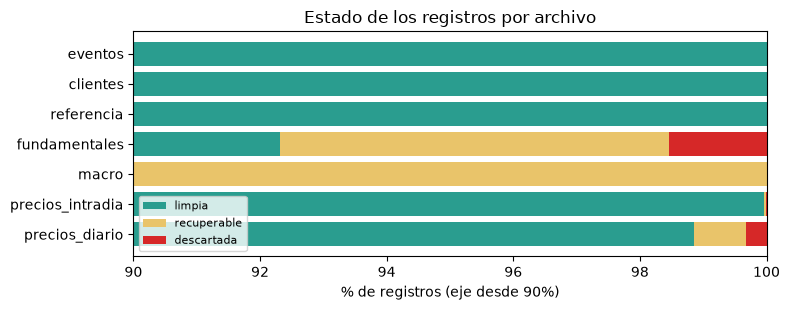

In [18]:
p = salvar.drop("TOTAL")[["% limpia", "% recuperable", "% descartada"]]
fig, ax = plt.subplots(figsize=(8, 3.2))
left = np.zeros(len(p))
for col, color in [("% limpia", "#2a9d8f"), ("% recuperable", "#e9c46a"), ("% descartada", "#d62828")]:
    ax.barh(p.index, p[col], left=left, color=color, label=col.strip("% ")); left += p[col].values
ax.set_xlim(90, 100); ax.set_xlabel("% de registros (eje desde 90%)"); ax.legend(loc="lower left", fontsize=8)
ax.set_title("Estado de los registros por archivo")
plt.tight_layout(); plt.show()

## A10. ¿Qué fuente de precios es la verdad? Diario vs. intradía

Viene de `notebooks/etapa2_find_the_signal.py` (`main`) y `databricks/05_reporte_calidad.py` (`dev_databricks`).
Se reconstruye el cierre diario con la última barra intradía del día y se compara con el archivo diario.

In [19]:
def silver_precios(d, estado):
    s = orden(d[estado.reindex(d.index) != "descartada"]).copy()
    for c in OHLCV:
        s[c] = to_num(s[c])
    escala = ((s.close > s.high) | (s.close < s.low)) & (s.close / 100).between(s.low, s.high)
    s.loc[escala, "close"] = s.loc[escala, "close"] / 100
    s.loc[s.volume == 99_999_999, "volume"] = np.nan
    return s

sdia, sint = silver_precios(pdia, est_dia), silver_precios(pint, est_int)
cierre_int = sint.assign(dia=sint.ts.dt.normalize()).groupby(["dia", "asset_c"]).close.last().unstack()
px_usd = sdia.pivot(index="ts", columns="asset_c", values="close")
comun = px_usd.index.intersection(cierre_int.index)
a, b = px_usd.loc[comun], cierre_int.loc[comun]
dif = (b / a - 1) * 100
rec = pd.DataFrame({
    "días comunes": len(comun),
    "dif. media abs. %": dif.abs().mean(),
    "% días con dif. > 1%": (dif.abs() > 1).mean() * 100,
    "corr. de retornos": [a[c].pct_change().corr(b[c].pct_change()) for c in a.columns],
}).round(2)
display(rec)
print(f"En total, {(dif.abs() > 1).sum().sum():,} de {dif.size:,} días-activo ({(dif.abs() > 1).values.mean():.1%}) difieren más de 1%.")

,días comunes,dif. media abs. %,% días con dif. > 1%,corr. de retornos
asset_c,,,,
VF_A01,271,6.02,85.24,-0.01
VF_A02,271,8.91,94.83,0.11
VF_A03,271,11.90,95.57,0.07
VF_A04,271,15.53,91.14,-0.01
VF_A05,271,18.95,96.31,0.05
VF_A06,271,16.23,98.89,0.13
VF_A07,271,17.30,97.42,0.07
VF_A08,271,21.04,97.42,0.06


En total, 2,051 de 2,168 días-activo (94.6%) difieren más de 1%.


Si fueran la misma fuente, casi todo estaría en ±1% y los retornos se correlacionarían cerca de 1. Aquí los retornos no se correlacionan.
**Decisión (etapa 2): el diario es la fuente de verdad**, porque reacciona en la dirección del evento en 4 de 5 eventos; el intradía solo en 1.
El intradía queda como historia previa a ago-2025.

# Parte B · Exploración en soles (PEN)

Se usan los precios diarios ya curados (`sdia`): sin duplicados, alias homologados y el close ×100 corregido.

## B1. Tipo de cambio USD/PEN

,USD/PEN
inicio,3.7233
fin,3.6802
variación %,-1.1576
mín,3.6669
máx,3.8268
vol. anual %,2.7813
peor día %,-0.4962
días de precio sin TC,0.0000


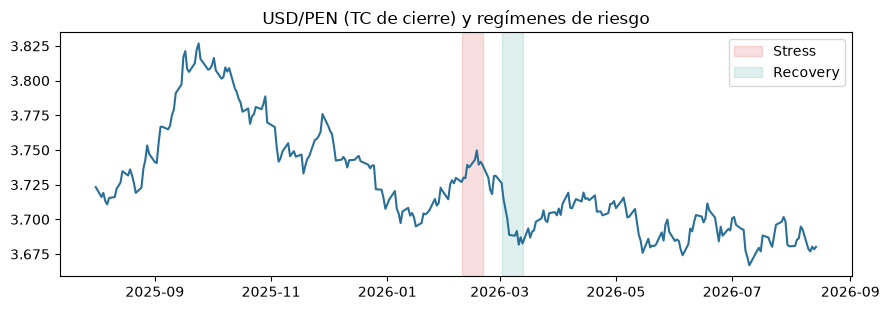

In [20]:
macro = m.set_index("ts").sort_index()
fx = macro.usd_pen
fx_d = fx.reindex(px_usd.index.union(fx.index)).ffill().reindex(px_usd.index)
fx_ret = fx_d.pct_change().dropna()
display(pd.Series({
    "inicio": fx.iloc[0], "fin": fx.iloc[-1], "variación %": (fx.iloc[-1] / fx.iloc[0] - 1) * 100,
    "mín": fx.min(), "máx": fx.max(), "vol. anual %": fx_ret.std() * ANN * 100, "peor día %": fx_ret.min() * 100,
    "días de precio sin TC": int(fx.reindex(px_usd.index).isna().sum()),
}).round(4).to_frame("USD/PEN"))

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(fx.index, fx.values, color="#2a6f97")
for r_, col in [("Stress", "#d62828"), ("Recovery", "#2a9d8f")]:
    d = macro.index[macro.risk_regime == r_]
    ax.axvspan(d.min(), d.max(), color=col, alpha=0.15, label=r_)
ax.set_title("USD/PEN (TC de cierre) y regímenes de riesgo"); ax.legend()
plt.tight_layout(); plt.show()

El sol se **apreció** 1,2% y el TC se movió poco (volatilidad anual ~2,8%, frente a 15–45% de las acciones).

## B2. Retorno y riesgo por activo en PEN

In [21]:
refi = ref.set_index("asset_id")
px = px_usd.mul(fx_d, axis=0)
r = px.pct_change().dropna()

def max_dd(nav):
    return (nav / nav.cummax() - 1).min()

tabla = pd.DataFrame({
    "nombre": refi.name, "sector": refi.sector, "país": refi.country,
    "ret. PEN %": (px.iloc[-1] / px.iloc[0] - 1) * 100,
    "ret. USD %": (px_usd.iloc[-1] / px_usd.iloc[0] - 1) * 100,
    "vol. PEN %": r.std() * ANN * 100,
    "max DD PEN %": px.apply(max_dd) * 100,
    "últ. 60d PEN %": (px.iloc[-1] / px.iloc[-61] - 1) * 100,
    "Sharpe aprox.": r.mean() / r.std() * ANN,
})
tabla["aporte FX (pp)"] = tabla["ret. PEN %"] - tabla["ret. USD %"]
ew = r.mean(axis=1); nav_ew = (1 + ew).cumprod()
display(tabla.sort_values("ret. PEN %", ascending=False).round(2))
print(f"Cartera equiponderada en PEN: retorno {(nav_ew.iloc[-1]-1)*100:.1f}% · vol {ew.std()*ANN*100:.1f}% · max DD {max_dd(nav_ew)*100:.1f}%")
print(f"Activos con retorno positivo: {(tabla['ret. PEN %'] > 0).sum()} de {len(tabla)}")

,nombre,sector,país,ret. PEN %,ret. USD %,vol. PEN %,max DD PEN %,últ. 60d PEN %,Sharpe aprox.,aporte FX (pp)
VF_A05,Aurora Health,Health Care,United States,30.40,31.93,24.36,-14.98,8.59,1.14,-1.53
VF_A04,Lima Financial,Financials,Peru,19.08,20.47,28.42,-16.61,-4.86,0.72,-1.39
VF_A01,Andes Consumer,Consumer Staples,Colombia,-11.07,-10.03,20.13,-29.03,-16.13,-0.44,-1.04
VF_A02,Pacifica Digital,Technology,Peru,-14.82,-13.82,44.80,-56.18,-7.46,-0.11,-1.00
VF_A08,Atlas Utilities,Utilities,United States,-15.15,-14.16,15.52,-21.80,-2.22,-0.91,-0.99
VF_A06,Norte Industrials,Industrials,Mexico,-23.33,-22.43,33.52,-38.24,-2.92,-0.57,-0.90
VF_A03,Cordillera Energy,Energy,Colombia,-27.33,-26.48,35.21,-44.06,-12.51,-0.67,-0.85
VF_A07,Sierra Materials,Materials,Chile,-27.53,-26.68,38.56,-38.68,-25.79,-0.59,-0.85


Cartera equiponderada en PEN: retorno -7.2% · vol 16.0% · max DD -21.3%
Activos con retorno positivo: 2 de 8


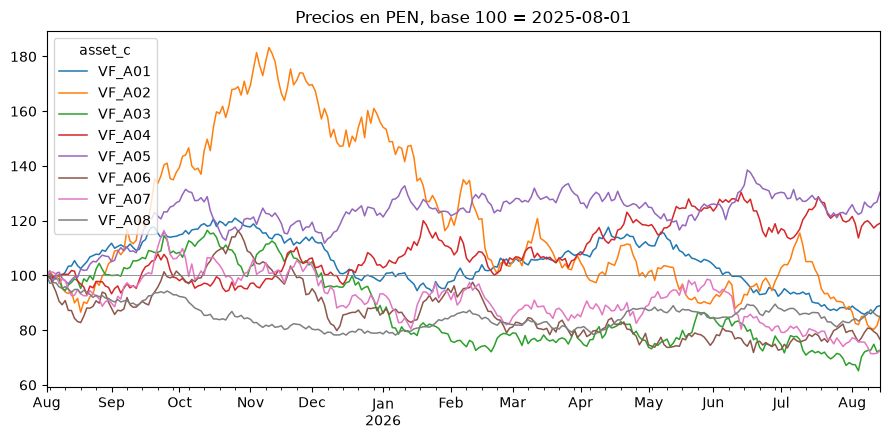

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.5))
(px / px.iloc[0] * 100).plot(ax=ax, lw=1.1)
ax.axhline(100, color="grey", lw=0.6); ax.set_title("Precios en PEN, base 100 = 2025-08-01"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## B3. Distribución de retornos diarios

,media %,desv. %,asimetría,curtosis exceso,peor día %,fecha peor,días < -3%,% días < -3%
asset_c,,,,,,,,
VF_A01,-0.035,1.268,0.175,-0.017,-3.376,2026-07-15,1,0.370
VF_A02,-0.020,2.822,-0.068,-0.019,-9.022,2026-06-10,36,13.333
VF_A03,-0.094,2.218,0.224,0.220,-5.274,2025-12-05,27,10.000
VF_A04,0.081,1.790,-0.018,-0.125,-4.880,2026-02-09,16,5.926
VF_A05,0.110,1.534,0.052,-0.312,-3.968,2025-10-15,6,2.222
VF_A06,-0.076,2.111,-0.000,-0.309,-5.810,2026-06-18,22,8.148
VF_A07,-0.090,2.429,-0.056,0.089,-6.669,2025-12-11,24,8.889
VF_A08,-0.056,0.978,-0.091,-0.473,-2.846,2025-08-04,0,0.000


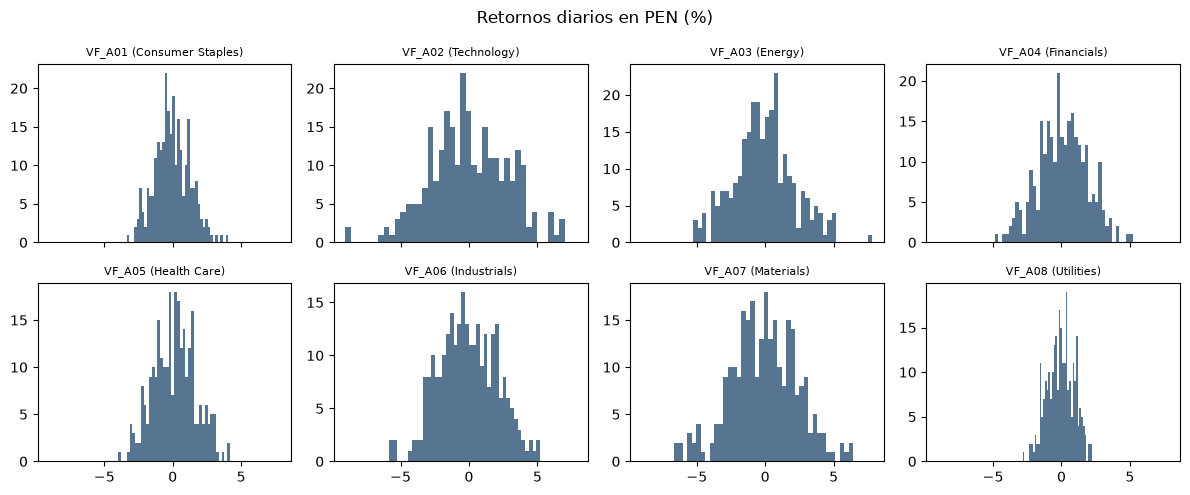

In [23]:
dist = pd.DataFrame({
    "media %": r.mean() * 100, "desv. %": r.std() * 100, "asimetría": r.skew(), "curtosis exceso": r.kurt(),
    "peor día %": r.min() * 100, "fecha peor": r.idxmin().dt.strftime("%Y-%m-%d"),
    "días < -3%": (r < -0.03).sum(), "% días < -3%": ((r < -0.03).mean() * 100),
}).round(3)
display(dist)
fig, axes = plt.subplots(2, 4, figsize=(12, 5), sharex=True)
for ax, a_ in zip(axes.flat, r.columns):
    ax.hist(r[a_] * 100, bins=40, color="#577590"); ax.set_title(f"{a_} ({refi.loc[a_, 'sector']})", fontsize=8)
fig.suptitle("Retornos diarios en PEN (%)"); plt.tight_layout(); plt.show()

Las colas son casi normales (curtosis en exceso entre −0,5 y 0,2): la volatilidad es una medida de riesgo razonable aquí.

## B4. Correlaciones y beta

,corr. media con el resto,beta vs market_factor
asset_c,,
VF_A01,0.14,0.43
VF_A02,0.15,1.47
VF_A03,0.18,1.08
VF_A04,0.21,1.05
VF_A05,0.17,0.80
VF_A06,0.20,1.19
VF_A07,0.14,1.08
VF_A08,0.12,0.35


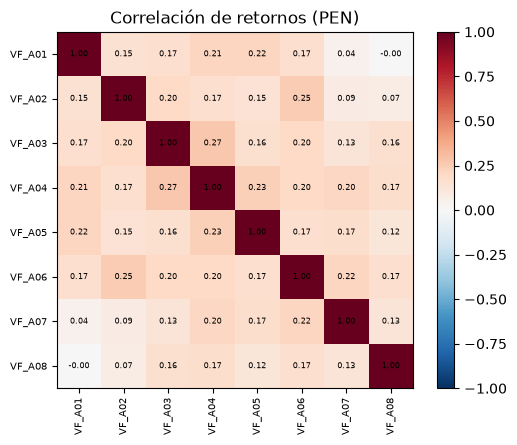

In [24]:
corr = r.corr()
mf = macro.market_factor.reindex(r.index)
display(pd.DataFrame({"corr. media con el resto": (corr.sum() - 1) / (len(corr) - 1),
                      "beta vs market_factor": r.apply(lambda s: s.cov(mf) / mf.var())}).round(2))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(8), corr.columns, rotation=90, fontsize=7); ax.set_yticks(range(8), corr.index, fontsize=7)
for i in range(8):
    for j in range(8):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im); ax.set_title("Correlación de retornos (PEN)"); plt.tight_layout(); plt.show()

## B5. Regímenes de riesgo

In [25]:
win = {k: (macro.index[macro.risk_regime == k].min(), macro.index[macro.risk_regime == k].max()) for k in ["Stress", "Recovery"]}
acum = pd.DataFrame({f"{k} ({a_:%d-%b} a {b_:%d-%b}) %": ((1 + r.loc[a_:b_]).prod() - 1) * 100 for k, (a_, b_) in win.items()})
acum["prom. diario Normal %"] = r[macro.risk_regime.reindex(r.index) == "Normal"].mean() * 100
acum.round(2).sort_values(acum.columns[0])

,Stress (09-Feb a 20-Feb) %,Recovery (02-Mar a 13-Mar) %,prom. diario Normal %
asset_c,,,
VF_A02,-24.04,9.92,0.05
VF_A06,-10.75,-0.34,-0.04
VF_A04,-10.46,0.13,0.13
VF_A07,-7.37,7.21,-0.10
VF_A08,-5.14,0.31,-0.04
VF_A05,-1.38,1.31,0.12
VF_A03,-1.04,-2.14,-0.09
VF_A01,2.93,1.67,-0.06


## B6. Eventos: retorno anormal acumulado (±5 días)
Retorno anormal = retorno del activo − retorno de la cartera equiponderada del mismo día.

In [26]:
ab = r.sub(ew, axis=0)
filas = []
for e in raw["eventos"].itertuples():
    fecha = pd.Timestamp(e.event_date)
    afectados = [e.scope] if e.scope in r.columns else list(refi.index[refi.sector == e.scope])
    t0 = r.index.searchsorted(fecha)
    for a_ in afectados:
        filas.append({"fecha": fecha.date(), "activo": a_, "tipo": e.event_type, "severidad": e.severity,
                      "titular": e.headline[:50],
                      "antes (-5 a -1) %": ab[a_].iloc[max(t0 - 5, 0):t0].sum() * 100,
                      "después (0 a +5) %": ab[a_].iloc[t0:t0 + 6].sum() * 100})
pd.DataFrame(filas).round(2)

,fecha,activo,tipo,severidad,titular,antes (-5 a -1) %,después (0 a +5) %
0,2026-02-10,VF_A02,Operational,High,Interrupción temporal de un proveedor crítico ...,7.95,-15.82
1,2026-04-06,VF_A03,Commodity,Medium,Mejora abrupta en margen de referencia energético,-4.13,3.46
2,2026-05-18,VF_A04,Earnings,Medium,Resultados superan expectativas internas del m...,7.45,-2.26
3,2026-06-08,VF_A07,Demand,High,Debilidad inesperada en demanda externa del se...,-4.73,-8.35
4,2026-07-21,VF_A02,Sector,Medium,Repricing de múltiplos en compañías de crecimi...,-8.37,-3.35


## B7. Fundamentales: ratios (sin efecto moneda) y montos en PEN

In [27]:
f = fun[~fun_desc].copy()
for c in NUMERICAS["fundamentales"]:
    f[c] = to_num(f[c])
# Q4-2024 de ISS_02 -> trimestre faltante 2025-06-30 (misma regla que 02_silver.py)
f["period_end"] = pd.to_datetime(f.period_end, format="%Y-%m-%d", errors="coerce")
for i in f.index[f.period_end.isna()]:
    faltan = sorted(set(f.period_end.dropna().unique()) - set(f.loc[f.issuer_c == f.at[i, "issuer_c"], "period_end"].dropna()))
    f.at[i, "period_end"] = faltan[0] if len(faltan) == 1 else pd.NaT
f = f.sort_values(["issuer_c", "period_end"])
f["cash_usd_m"] = f.groupby("issuer_c").cash_usd_m.ffill()
rev_ok = f.revenue_usd_m.where(f.revenue_usd_m >= 0.75 * f.groupby("issuer_c").revenue_usd_m.transform("median"))
f["margen neto"] = f.net_income_usd_m / rev_ok
f["margen EBITDA"] = f.ebitda_usd_m / rev_ok
f["crec. a/a"] = rev_ok / rev_ok.groupby(f.issuer_c).shift(4) - 1
f["deuda neta/EBITDA"] = (f.debt_usd_m - f.cash_usd_m) / (f.ebitda_usd_m * 4)
f["usd_pen cierre"] = f.period_end.map(lambda d: fx.loc[:d].iloc[-1] if d >= fx.index[0] else np.nan)
f["revenue PEN m"] = f.revenue_usd_m * f["usd_pen cierre"]
ult = f.groupby("issuer_c").tail(1).set_index("issuer_c")
res = ult.assign(period_end=ult.period_end.dt.strftime("%Y-%m-%d"))[["period_end", "crec. a/a", "margen neto", "margen EBITDA", "deuda neta/EBITDA", "revenue PEN m"]].copy()
res["trimestres con TC"] = f.groupby("issuer_c")["usd_pen cierre"].count()
res.index = refi.reset_index().set_index("issuer_id").loc[res.index, "asset_id"] + " · " + res.index
res.round(2)

,period_end,crec. a/a,margen neto,margen EBITDA,deuda neta/EBITDA,revenue PEN m,trimestres con TC
VF_A01 · ISS_01,2026-06-30,0.07,0.22,0.33,0.26,8230.58,4
VF_A02 · ISS_02,2026-06-30,0.10,0.14,0.27,0.23,11894.15,4
VF_A03 · ISS_03,2026-06-30,0.05,0.07,0.12,0.01,12544.68,4
VF_A04 · ISS_04,2026-06-30,0.10,0.20,0.30,0.29,17225.03,4
VF_A05 · ISS_05,2026-06-30,0.09,0.20,0.28,0.29,7935.95,4
VF_A06 · ISS_06,2026-06-30,NaN,0.08,0.16,0.62,11469.20,4
VF_A07 · ISS_07,2026-06-30,0.09,0.13,0.21,0.12,20161.64,4
VF_A08 · ISS_08,2026-06-30,0.04,0.08,0.12,-0.25,7704.47,4


Los ratios no dependen de la moneda. Los montos en soles solo existen para los 4 trimestres con TC (2025-09-30 a 2026-06-30).

## B8. Lectura por cliente (todo en PEN)

In [28]:
cl = raw["clientes"].assign(tol=lambda d: d.max_drawdown_tolerance_pct.astype(float))
alta_vol = list(tabla.index[tabla["vol. PEN %"] > 30])
print("Activos de alta volatilidad (vol. > 30%, supuesto para CL_02):", alta_vol)
cabe = pd.DataFrame({c.client_id: (-tabla["max DD PEN %"] <= c.tol) for c in cl.itertuples()})
fit = cabe.replace({True: "✓", False: "✗"})
fit.loc["activos que caben"] = cabe.sum().astype(str) + " de 8"
fit.loc["% del universo"] = (cabe.mean() * 100).round(1).astype(str) + "%"
print("¿El max drawdown en PEN de cada activo, solo, cabe en la tolerancia del cliente?")
display(fit)
cl.assign(dd_equiponderada_pen=round(max_dd(nav_ew) * 100, 1),
          cumple=lambda d: -d.dd_equiponderada_pen <= d.tol)[["client_id", "profile_name", "tol", "dd_equiponderada_pen", "cumple", "constraint"]]

Activos de alta volatilidad (vol. > 30%, supuesto para CL_02): ['VF_A02', 'VF_A03', 'VF_A06', 'VF_A07']
¿El max drawdown en PEN de cada activo, solo, cabe en la tolerancia del cliente?


,CL_01,CL_02,CL_03
VF_A01,✗,✗,✗
VF_A02,✗,✗,✗
VF_A03,✗,✗,✗
VF_A04,✓,✗,✗
VF_A05,✓,✗,✓
VF_A06,✗,✗,✗
VF_A07,✗,✗,✗
VF_A08,✓,✗,✗
activos que caben,3 de 8,0 de 8,1 de 8
% del universo,37.5%,0.0%,12.5%


,client_id,profile_name,tol,dd_equiponderada_pen,cumple,constraint
0,CL_01,Crecimiento Global,22.0,-21.3,True,Máx. 45% en un solo sector
1,CL_02,Patrimonio Estable,10.0,-21.3,False,Máx. 25% en activos de alta volatilidad
2,CL_03,Diversificación Regional,15.0,-21.3,False,Al menos 3 países y 3 sectores


# Conclusiones

### Calidad (Parte A)
1. **Se aprovecha el 99,99% de los registros** (541.319 de 541.363). Solo se descartan 44: 20 duplicados exactos y 24 barras intradía sin `close`.
   El 99,91% llega limpio y el 0,08% (452 registros) necesita una corrección determinística.
2. **Los duplicados no tienen conflicto**: todos son copias idénticas (0,32% del diario, 0,002% del intradía y 1 fila de fundamentales), así que se eliminan sin perder información.
   Tras deduplicar, **cada activo queda con el 100% de los registros esperados**: 271 días en el diario y 67.353 barras en el intradía.
3. **Hay nulos y números disfrazados de texto**: 33 volúmenes `N/A` y 48 con sufijo `K`. Hay que declararlos en la ingesta de Spark/SQL (`02_silver.py` ya lo hace).
4. **El 95% de la inflación está vacía, pero no es un error**: es un dato mensual en una tabla diaria y se rellena con forward-fill.
5. **Hay 7 alias de ID** (20 registros) y ninguno queda huérfano tras homologar: todas las relaciones entre tablas cierran al 100%.
6. **Un solo outlier grave**: VF_A06 con close de 3.589 el 2026-03-23 es un error de escala ×100 (3.589 ÷ 100 = 35,89, dentro del rango del día).
   Ojo: `src/analysis/clean.py` lo reemplaza por el promedio OHLC (35,03), mientras que `databricks/02_silver.py` lo divide entre 100. Conviene unificar en ÷100.
7. **El diccionario de datos se equivoca**: el intradía cubre de 2020 a 2026 (no de 2020 a 2022) y el diario termina el 2026-08-14 (no el 2026-07-21).
8. **El diario y el intradía son series distintas**: el 94,6% de los días-activo difiere más de 1% y los retornos no se correlacionan (−0,01 a 0,13). La fuente de verdad es el diario.

### Exploración en soles (Parte B)
1. **El tipo de cambio resta, pero no decide**: el sol se apreció 1,2% y cada activo rinde entre 0,9 y 1,5 pp menos en PEN que en USD. El ranking de activos no cambia.
2. **Solo 2 de 8 activos generan valor**: VF_A05 (+30,4%) y VF_A04 (+19,1%), y son también los de mejores fundamentales (margen neto del 20%).
3. **Repartir en partes iguales no sirve**: la cartera equiponderada cae −21,3% en el peor momento. Solo cabe en la tolerancia de CL_01 (22%) y rompe las de CL_02 (10%) y CL_03 (15%).
   Para CL_02, ningún activo por sí solo cabe en el 10%: la decisión es cuánto exponer y con qué colchón de liquidez.
4. **Los refugios en estrés son VF_A01 (+2,9%) y VF_A05 (−1,4%)**. VF_A02 cae −24% y VF_A04 cae −10,5% sin recuperarse en la ventana de Recovery.
5. **Los activos se mueven poco entre sí** (correlación media de 0,12 a 0,21): diversificar reduce el riesgo de verdad.
6. **Los eventos de severidad High se reflejan en el precio**: VF_A02 −15,8% y VF_A07 −8,4% de retorno anormal en los 5 días siguientes.